# Heat-Risk Screening — Deliverable 2

**Track:** Track 1 — Heat-risk screening

**Group:** Jonas Juchelka & Kriti Shrestha

**Dataset:** FAIRUrbTemp curated subset (Amini et al., 2026, *Scientific Data*) — Path wrt this notebook: `../archive/`

## 0. Setup & imports

In [1]:
from pathlib import Path
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    precision_score, recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)

print('Libraries loaded.')
print(f'pandas {pd.__version__}, numpy {np.__version__}, sklearn loaded')

Libraries loaded.
pandas 2.3.3, numpy 2.4.4, sklearn loaded


---

## 1. Deliverable 1 recap & Deliverable 2 goals

### 1.1 What Deliverable 1 established

In our first deliverable, we framed the heat screening question "*which locations experience the highest heat exposure, and how stable is that ranking?*" and audited the FAIRUrbTemp data. Its main outcomes:

- **A defensible analysis population.** Of 712 stations, 375 across 6 cities (Zurich, Basel, Bern, Birmingham, Amsterdam, Berlin) have at least 50% of summer 2019–2022 hours observed; Novi Sad and Biel fall outside the common window entirely.
- **Two candidate heat-risk metrics** per station — summer p95 of `ta` and the 30 °C exceedance rate — which agree strongly (Spearman ρ = 0.99).
- **The headline finding:** an *absolute* ranking is dominated by a single city — Zurich holds the entire top-15 — because **climate (between cities) swamps microclimate (within city)**. Threshold choice also churns the top of the ranking (a third of the top-15 changes between 28 °C and 32 °C).
- **The open question Deliverable 1 left for Deliverable 2:** can the within-city microclimate signal be isolated and predicted, so that a planner gets guidance *inside* their own city rather than a re-statement of which cities are warm?

### 1.2 Goal and motivation for Deliverable 2 (D2)

In D2, we turn that open question into a **supervised classification task with rigorous validation**. D1 *described* heat risk. D2 now tests whether heat risk can be *predicted from station context*. This prediction step is what a screening tool ultimately requires. If risk can be predicted from location, planners can prioritise sites, including ones without sensors.

In this deliverable, a station's heat risk is measured by the 95th percentile (p95) of its hourly summer air temperature. This is the temperature that its hottest ~5% of summer hours reach or exceed. A station counts as a hotspot if its p95 is in the top quartile (defined precisely in Section 2.2). We justify both choices and test their sensitivity in Section 5.5.

Sustained high air temperatures cause heat stress. They raise the risk of heat stroke, dehydration, and cardiovascular strain, and excess mortality during heat waves is well documented, especially among elderly people, young children, and people with pre-existing conditions. Exposure is local. People live, work, and commute at street level, where summer temperatures can differ by several degrees within one city (D1, Section 4.4). Knowing which locations run hottest tells a city where shade, greenery, or cooling centres protect the most people.

We set up two classification targets and train models for both. Both targets use the same features, the same pipeline, and the same cross-validation. This keeps the comparison fair.

- **Model A (absolute hotspot):** is a station in the top quartile of summer p95 `ta` *across all cities*? We expect geography (including which city) to predict this well, because absolute heat is climate-driven.
- **Model B (local hotspot):** is a station in the top quartile *within its own city*? This removes the climate signal and leaves only microclimate.

Our goal in this deliverable is to test how much station geography can explain in each case. If Model A works but Model B does not, we learn that heat risk is predictable *between* cities but not *within* them from the geography we have. It would tell us which data is missing (for example land cover). We also want to turn the working model into a usable screening rule. Its decision threshold plays that role. It answers a practical question. *How aggressively should stations be flagged for mitigation investigation?*

---

## 2. Data loading & target construction

This section is self-contained — it re-parses the FAIRUrbTemp SEF files, recomputes the per-station summer heat-risk metric, and builds **two** binary targets that we will contrast:

- `is_hotspot_absolute` — top quartile of summer p95 `ta` across all stations (climate-driven).
- `is_local_hotspot` — top quartile *within each city* (microclimate-only).

### 2.1 Load the hourly data (own copy of the SEF parser)

In [2]:
ARCHIVE = Path('../archive')
HOURLY_DIR = ARCHIVE / 'data' / 'hourly'
META_DIR   = ARCHIVE / 'data' / 'metadata'
CACHE_DIR  = Path('cache'); CACHE_DIR.mkdir(exist_ok=True)
HOURLY_PARQUET = CACHE_DIR / 'hourly_long.parquet'

assert HOURLY_DIR.exists(), f'Dataset not found at {HOURLY_DIR.resolve()}'

def parse_sef_file(path: Path) -> pd.DataFrame:
    """Parse one FAIRUrbTemp SEF TSV into long format (city, station_id, datetime, ta).

    station_id is the filename stem before '_AirTemp_' (handles 'D2195' and
    'AWEL_Blumenfeld'), Unicode-normalized to NFC so umlaut station names match
    the metadata TSVs (the filesystem stores names as NFD on macOS, metadata is NFC).
    '-999' is a missing-value sentinel folded into NA alongside the literal 'NA'.
    """
    df = pd.read_csv(
        path, sep='\t', skiprows=12, na_values=['NA', '-999', '-999.0'],
        dtype={'Year':'Int64','Month':'Int64','Day':'Int64','Hour':'Int64','Minute':'Int64'},
        low_memory=False,
    )
    parts = df[['Year','Month','Day','Hour','Minute']].rename(columns=str.lower)
    return pd.DataFrame({
        'city': path.parent.name,
        'station_id': unicodedata.normalize('NFC', path.stem.split('_AirTemp_')[0]),
        'datetime': pd.to_datetime(parts),
        'ta': pd.to_numeric(df['Value'], errors='coerce'),
    })

if HOURLY_PARQUET.exists():
    print(f'Loading cached parquet {HOURLY_PARQUET} ...')
    hourly = pd.read_parquet(HOURLY_PARQUET)
else:
    print('Parsing SEF files (first run, ~1-2 min) ...')
    files = [f for c in sorted(HOURLY_DIR.iterdir()) if c.is_dir()
             for f in sorted(c.glob('*.tsv'))]
    hourly = pd.concat([parse_sef_file(f) for f in files], ignore_index=True)
    hourly['city'] = hourly['city'].astype('category')
    hourly['station_id'] = hourly['station_id'].astype('category')
    hourly.to_parquet(HOURLY_PARQUET, index=False)
    print(f'Saved {HOURLY_PARQUET} ({HOURLY_PARQUET.stat().st_size/1e6:.1f} MB)')

print(f'Loaded {len(hourly):,} rows, {hourly.station_id.nunique()} stations')

Loading cached parquet cache/hourly_long.parquet ...


Loaded 16,969,491 rows, 712 stations


### 2.2 Per-station risk metric and the two hotspot labels

We use p95 rather than the maximum because a single hottest hour is noisy. p95 reflects heat that is reached repeatedly across the summer. We use a quantile cut-off rather than a fixed temperature (such as 30 °C) because a fixed value produces almost no positives in cool cities and many in warm ones, which makes one shared classifier hard to train and compare. The top quartile gives a balanced label (~25% positives) and matches the screening use case of flagging a shortlist of stations for investigation. Section 5.5 tests how sensitive the results are to both choices.

In [3]:
STUDY_YEARS = [2019, 2020, 2021, 2022]
SUMMER_MONTHS = [6, 7, 8]
MAX_OBS = len(STUDY_YEARS) * 92 * 24    # theoretical max summer hours
MIN_AVAILABILITY = 0.50

m = (hourly['datetime'].dt.year.isin(STUDY_YEARS)
     & hourly['datetime'].dt.month.isin(SUMMER_MONTHS))
summer = hourly.loc[m].dropna(subset=['ta']).copy()

n_obs = summer.groupby('station_id', observed=True).size()
keep = n_obs[n_obs >= MIN_AVAILABILITY * MAX_OBS].index
summer = summer[summer['station_id'].isin(keep)]

risk = (summer.groupby(['city', 'station_id'], observed=True)['ta']
        .quantile(0.95).reset_index(name='p95'))

# Target A: absolute top quartile across all stations (climate-driven)
risk['is_hotspot_absolute'] = (risk['p95'] >= risk['p95'].quantile(0.75)).astype(int)

# Target B: within-city top quartile (microclimate only)
risk['is_local_hotspot'] = (
    risk.groupby('city', observed=True)['p95']
        .transform(lambda s: (s >= s.quantile(0.75)).astype(int))
)

print(f'Stations after availability filter: {len(risk)} across {risk.city.nunique()} cities')
print(f'Absolute hotspot rate: {risk.is_hotspot_absolute.mean():.0%}')
print(f'Local hotspot rate:    {risk.is_local_hotspot.mean():.0%}')
print('\nAbsolute hotspots by city (expect Zurich-dominated):')
print(risk[risk.is_hotspot_absolute == 1].city.value_counts().to_string())
print('\nLocal hotspots by city (expect spread across cities):')
print(risk[risk.is_local_hotspot == 1].city.value_counts().to_string())

assert 350 <= len(risk) <= 400, f'unexpected station count {len(risk)}'
for col in ['is_hotspot_absolute', 'is_local_hotspot']:
    assert 0.20 <= risk[col].mean() <= 0.30, f'{col} rate off'

Stations after availability filter: 375 across 6 cities
Absolute hotspot rate: 25%
Local hotspot rate:    26%

Absolute hotspots by city (expect Zurich-dominated):
city
Zurich        72
Basel         11
Bern          11
Berlin         1
Amsterdam      0
Biel           0
Birmingham     0
Freiburg       0
NoviSad        0

Local hotspots by city (expect spread across cities):
city
Zurich        46
Basel         25
Bern          14
Birmingham     5
Amsterdam      3
Berlin         3
Biel           0
Freiburg       0
NoviSad        0


### 2.3 Merge station metadata and engineer features

In [4]:
station_meta = pd.concat(
    [pd.read_csv(p, sep='\t') for p in sorted(META_DIR.glob('*/station_metadata_*.tsv'))],
    ignore_index=True,
)
# NFC-normalize so umlaut station ids match the (NFC) parser output
station_meta['station_id'] = station_meta['station_id'].map(
    lambda s: unicodedata.normalize('NFC', str(s))
)

def parse_height(v):
    """'4 m' -> 4.0 ; '2-3 m' -> 2.5 ; 2.0 -> 2.0 ; junk -> NaN"""
    if pd.isna(v): return np.nan
    s = str(v).lower().replace('m', '').strip()
    if '-' in s:
        a, b = s.split('-', 1)
        try: return (float(a) + float(b)) / 2
        except ValueError: return np.nan
    try: return float(s)
    except ValueError: return np.nan

station_meta['sensor_height_parsed'] = station_meta['sensor_height_m'].apply(parse_height)

df = risk.merge(
    station_meta[['station_id', 'latitude', 'longitude', 'sensor_height_parsed']],
    on='station_id', how='left',
)

# City centroid over the modeling stations (pure geography, target-independent -> no leakage)
cent = (df.groupby('city', observed=True)[['latitude', 'longitude']]
          .mean().rename(columns={'latitude': 'clat', 'longitude': 'clon'}))
df = df.merge(cent, on='city')

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1); dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat/2)**2
         + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2)
    return 2 * R * np.arcsin(np.sqrt(a))

df['distance_to_centroid'] = haversine_km(df.latitude, df.longitude, df.clat, df.clon)
df['city'] = df['city'].astype(str)

NUM_FEATURES = ['latitude', 'longitude', 'distance_to_centroid', 'sensor_height_parsed']
CAT_FEATURES = ['city']
FEATURES = NUM_FEATURES + CAT_FEATURES

print(df[NUM_FEATURES].describe().round(2))
print('\nMissing per numeric feature:'); print(df[NUM_FEATURES].isna().sum())
# Guard: every station must have matched metadata coordinates (the 17 umlaut Basel
# stations previously failed to match before the NFC fix above).
assert df[['latitude', 'longitude']].notna().all().all(), \
    'some stations have no coordinates -> station_id mismatch with metadata'
print(f'\nAll {len(df)} stations matched metadata coordinates.')

       latitude  longitude  distance_to_centroid  sensor_height_parsed
count    375.00     375.00                375.00                375.00
mean      47.89       7.63                  3.43                  2.98
std        1.56       2.47                  2.57                  0.25
min       46.90      -2.06                  0.10                  2.00
25%       47.36       7.56                  1.83                  3.00
50%       47.41       8.48                  2.99                  3.00
75%       47.55       8.53                  4.24                  3.00
max       52.56      13.40                 18.95                  4.00

Missing per numeric feature:
latitude                0
longitude               0
distance_to_centroid    0
sensor_height_parsed    0
dtype: int64

All 375 stations matched metadata coordinates.


**Feature rationale (preprocessing, see Section 3):**
- Numeric geography (`latitude`, `longitude`, `distance_to_centroid`) and `sensor_height_parsed` are pure metadata — independent of the temperature record that defines the targets, so they cannot leak a label.
- `city` is included as a categorical feature. For **Model A (absolute)** it is a strong, legitimate climate proxy. For **Model B (within-city)** it carries no information by construction (the label is balanced within each city), so it cannot help — making the contrast clean on a single shared feature set.
- `distance_to_centroid` is the within-city position signal (centre → denser → warmer). Target-independent, so one global centroid per city introduces no leakage.
- `sensor_height_m` is parsed from free text and has gaps; imputed inside the pipeline so the fill value is learned per fold.
- `altitude_m` is excluded — populated only for Zurich/Berlin/NoviSad, unusable across the 6 modeling cities.

---

## 3. Preprocessing pipeline

A single `ColumnTransformer` handles both feature types and is wrapped with the classifier in a `Pipeline`, so all fitted state (imputer median, scaler statistics, one-hot categories) is learned on **training folds only** during cross-validation — no leakage. The same pipeline definition is reused for every model and both targets.

- Numeric: median-impute `sensor_height_parsed` → standardize.
- Categorical (`city`): one-hot encode.

In [5]:
def make_pipeline(classifier):
    """Shared ColumnTransformer (numeric impute+scale, city one-hot) + classifier."""
    pre = ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), NUM_FEATURES),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
    ])
    return Pipeline([('pre', pre), ('clf', classifier)])

X = df[FEATURES].copy()
y_abs = df['is_hotspot_absolute'].copy()
y_loc = df['is_local_hotspot'].copy()

# smoke test (not evaluation)
_smoke = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
_smoke.fit(X, y_abs)
print('Pipeline smoke test OK; predict shape:', _smoke.predict(X).shape)
assert _smoke.predict_proba(X).shape == (len(X), 2)

Pipeline smoke test OK; predict shape: (375,)


---

## 4. Models: baseline → improved

Three models, escalating in flexibility, on the shared pipeline:

1. **Baseline 1 — `DummyClassifier(stratified)`** — the no-skill floor.
2. **Baseline 2 — `LogisticRegression(class_weight='balanced')`** — interpretable; coefficients show which factors drive the prediction.
3. **Improved — `RandomForestClassifier(class_weight='balanced')`** — captures non-linear structure.

`class_weight='balanced'` handles the ~25/75 imbalance without resampling. Hyperparameters are tuned with a small cross-validated grid search (`GridSearchCV`, scored by average precision) on the **absolute** target, since that is the model we will actually deploy for screening. With only 375 stations, flexible models overfit easily. We therefore expect the tuning to prefer constrained settings, such as a shallow `max_depth` for the forest, trading a little bias for lower variance. The same tuned pipelines are then re-evaluated on the within-city target for the contrast.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dummy = make_pipeline(DummyClassifier(strategy='stratified', random_state=RANDOM_STATE))

logit = GridSearchCV(
    make_pipeline(LogisticRegression(class_weight='balanced', max_iter=1000,
                                     random_state=RANDOM_STATE)),
    param_grid={'clf__C': [0.1, 1.0, 10.0]},
    scoring='average_precision', cv=cv, n_jobs=-1,
)

rf = GridSearchCV(
    make_pipeline(RandomForestClassifier(class_weight='balanced',
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    param_grid={'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 5, None]},
    scoring='average_precision', cv=cv, n_jobs=-1,
)

logit.fit(X, y_abs)
rf.fit(X, y_abs)
print('LogReg best params:', logit.best_params_)
print('RF best params:    ', rf.best_params_)

LogReg best params: {'clf__C': 1.0}
RF best params:     {'clf__max_depth': 3, 'clf__n_estimators': 200}


---

## 5. Validation & evaluation

We use **5-fold stratified cross-validation** and evaluate on **out-of-fold** predictions (every metric reflects stations the model did not train on). We emphasise **PR-AUC (average precision)** because hotspots are the minority class. The central question we evaluate is how the two targets **compare** under identical validation.

Cross-city transfer (train on some cities, test on a held-out city) is a stronger robustness test but we have decided to keep it out-of-scope for this deliverable and deferred to the next deliverable.

### 5.1 The contrast: absolute vs within-city

In [7]:
models = {
    'Dummy (stratified)': dummy,
    'LogReg (balanced)':  logit.best_estimator_,
    'RandomForest':       rf.best_estimator_,
}
targets = {'absolute': y_abs, 'within-city': y_loc}

def oof_proba(estimator, yt):
    cv_t = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_predict(estimator, X, yt, cv=cv_t, method='predict_proba')[:, 1]

proba = {}
rows = []
for tname, yt in targets.items():
    for mname, est in models.items():
        p = oof_proba(est, yt)
        proba[(tname, mname)] = p
        rows.append({'target': tname, 'model': mname,
                     'ROC-AUC': roc_auc_score(yt, p),
                     'PR-AUC': average_precision_score(yt, p),
                     'baseline_rate': yt.mean()})
contrast = pd.DataFrame(rows).set_index(['target', 'model']).round(3)
print(contrast)

# Model A (absolute) should clearly beat its dummy; Model B (within-city) should not.
abs_rf = contrast.loc[('absolute', 'RandomForest'), 'ROC-AUC']
abs_dum = contrast.loc[('absolute', 'Dummy (stratified)'), 'ROC-AUC']
assert abs_rf > abs_dum + 0.10, 'absolute model should clearly beat its dummy'
print('\nContrast confirmed: absolute model has real skill; within-city near chance.')

                                ROC-AUC  PR-AUC  baseline_rate
target      model                                             
absolute    Dummy (stratified)    0.521   0.262          0.253
            LogReg (balanced)     0.650   0.342          0.253
            RandomForest          0.689   0.388          0.253
within-city Dummy (stratified)    0.491   0.253          0.256
            LogReg (balanced)     0.392   0.209          0.256
            RandomForest          0.502   0.267          0.256

Contrast confirmed: absolute model has real skill; within-city near chance.


### 5.2 ROC and Precision-Recall curves (working model = absolute)

We pick the better absolute model (by PR-AUC) as the screening model and plot its curves, with the dummy and the within-city version of the same model overlaid to make the contrast visible.

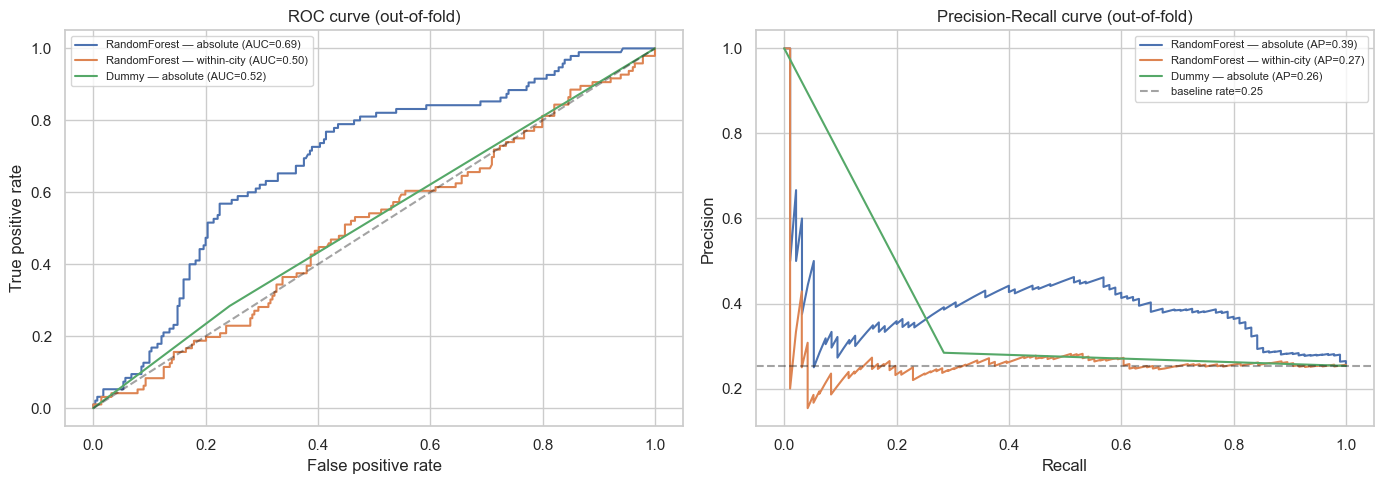

In [8]:
best_name = ('RandomForest'
             if contrast.loc[('absolute', 'RandomForest'), 'PR-AUC']
                >= contrast.loc[('absolute', 'LogReg (balanced)'), 'PR-AUC']
             else 'LogReg (balanced)')
p_best = proba[('absolute', best_name)]

curves = {
    f'{best_name} — absolute':    (y_abs, proba[('absolute', best_name)]),
    f'{best_name} — within-city': (y_loc, proba[('within-city', best_name)]),
    'Dummy — absolute':           (y_abs, proba[('absolute', 'Dummy (stratified)')]),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, (yt, p) in curves.items():
    fpr, tpr, _ = roc_curve(yt, p)
    axes[0].plot(fpr, tpr, label=f'{label} (AUC={roc_auc_score(yt, p):.2f})')
    prec, rec, _ = precision_recall_curve(yt, p)
    axes[1].plot(rec, prec, label=f'{label} (AP={average_precision_score(yt, p):.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set(title='ROC curve (out-of-fold)', xlabel='False positive rate',
            ylabel='True positive rate')
axes[1].axhline(y_abs.mean(), ls='--', color='k', alpha=0.4,
                label=f'baseline rate={y_abs.mean():.2f}')
axes[1].set(title='Precision-Recall curve (out-of-fold)', xlabel='Recall',
            ylabel='Precision')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.3 Threshold tuning — the screening decision (on the working absolute model)

A lower threshold flags more stations (higher recall, more false alarms). We make the trade-off explicit with a cost ratio: missing a real hotspot is treated as `COST_FN` times worse than a false alarm.

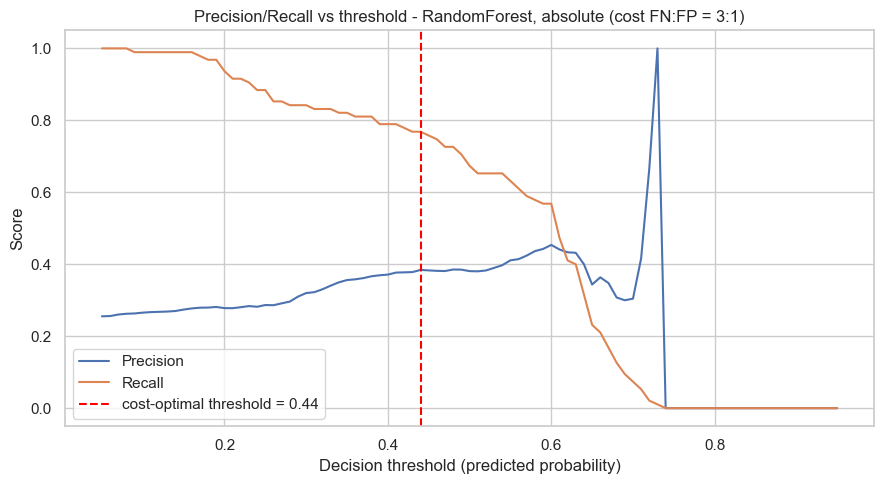

Screening model: RandomForest (absolute target)
Cost-optimal threshold: 0.44
Metrics at chosen threshold: {'Precision': 0.384, 'Recall': 0.768, 'F1': 0.512, 'MCC': 0.305}


In [9]:
def metrics_at(yt, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {'Precision': precision_score(yt, yhat, zero_division=0),
            'Recall':    recall_score(yt, yhat, zero_division=0),
            'F1':        f1_score(yt, yhat, zero_division=0),
            'MCC':       matthews_corrcoef(yt, yhat)}

COST_FN, COST_FP = 3, 1   # missing a hotspot is 3x worse than a false alarm
thresholds = np.linspace(0.05, 0.95, 91)
costs, precs, recs = [], [], []
for t in thresholds:
    yhat = (p_best >= t).astype(int)
    fp = int(((yhat == 1) & (y_abs == 0)).sum())
    fn = int(((yhat == 0) & (y_abs == 1)).sum())
    costs.append(COST_FP * fp + COST_FN * fn)
    precs.append(precision_score(y_abs, yhat, zero_division=0))
    recs.append(recall_score(y_abs, yhat, zero_division=0))
t_star = float(thresholds[int(np.argmin(costs))])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, precs, label='Precision')
ax.plot(thresholds, recs, label='Recall')
ax.axvline(t_star, color='red', ls='--', label=f'cost-optimal threshold = {t_star:.2f}')
ax.set(title=f'Precision/Recall vs threshold - {best_name}, absolute (cost FN:FP = {COST_FN}:{COST_FP})',
       xlabel='Decision threshold (predicted probability)', ylabel='Score')
ax.legend(); plt.tight_layout(); plt.show()

print(f'Screening model: {best_name} (absolute target)')
print(f'Cost-optimal threshold: {t_star:.2f}')
print('Metrics at chosen threshold:',
      {k: round(v, 3) for k, v in metrics_at(y_abs, p_best, t_star).items()})

### 5.4 Confusion matrix and error analysis (absolute model)

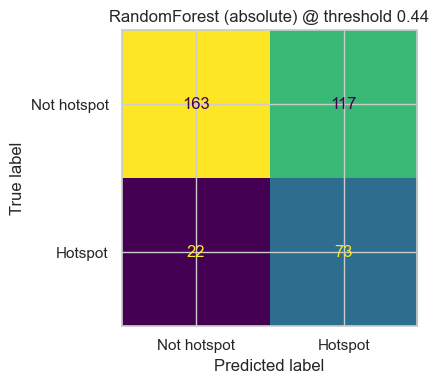

Misclassified stations: 139 of 375
By city:
city
Zurich    112
Bern       15
Basel      11
Berlin      1
Name: count, dtype: int64
  city               station_id  p95 (degC)  distance to centroid (km)  sensor height (m)  y_true  P(hotspot)
Berlin                spandauer     30.3600                   9.528990                2.0       1    0.084601
 Basel Hegenheimermattweg..119.     30.7000                   4.033853                3.0       1    0.162784
 Basel          Westquaistrasse     30.5000                   3.943526                3.0       1    0.176761
 Basel              Rankstrasse     30.4800                   1.583452                3.0       1    0.190066
 Basel     In.den.Schorenmatten     30.4335                   2.203555                3.0       1    0.191348
 Basel          Rue.de.Mulhouse     30.7000                   4.982787                3.0       1    0.197408
 Basel           Gellertstrasse     30.4140                   0.647612                3.0       1  

In [10]:
yhat_star = (p_best >= t_star).astype(int)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_abs, yhat_star),
                       display_labels=['Not hotspot', 'Hotspot']).plot(ax=ax, colorbar=False)
ax.set_title(f'{best_name} (absolute) @ threshold {t_star:.2f}')
plt.tight_layout(); plt.show()

err = df.assign(y_true=y_abs.values, y_pred=yhat_star, p_hot=p_best)
misclassified = err[err.y_true != err.y_pred][
    ['city', 'station_id', 'p95', 'distance_to_centroid', 'sensor_height_parsed', 'y_true', 'p_hot']
].sort_values('p_hot').rename(columns={
    'p95': 'p95 (degC)', 'distance_to_centroid': 'distance to centroid (km)',
    'sensor_height_parsed': 'sensor height (m)', 'p_hot': 'P(hotspot)',
})
print(f'Misclassified stations: {len(misclassified)} of {len(err)}')
print('By city:'); print(misclassified.city.value_counts())
print(misclassified.head(10).to_string(index=False))

**Interpretation.**

- **The absolute model has modest real skill.** Out-of-fold, RandomForest reaches ROC-AUC 0.689 and PR-AUC 0.388, versus the stratified dummy's 0.521 / 0.262 — a clear ~0.17 ROC-AUC gain over no-skill. LogReg is intermediate (0.650 / 0.342). The PR-AUC of 0.388 against a 0.25 baseline rate confirms the lift is real, not an artefact of class imbalance.
- **The within-city model has no skill, which is the key finding.** On the same features and pipeline, RandomForest scores ROC-AUC 0.502 (chance is 0.50) and PR-AUC 0.267 (baseline 0.256); LogReg is actually below chance at 0.392. *This means: heat risk is predictable between cities from geography, but not within a city. Once the climate signal is removed, the geography we have carries essentially no information about which station is a local hotspot.*
- **At the cost-optimal threshold (0.44) on the absolute model**, precision = 0.384 and recall = 0.768 — i.e. the screen catches about 77% of true absolute hotspots, but only ~38% of flagged stations are genuine (the rest are false alarms), reflecting the deliberate 3:1 cost weighting that favours not missing a hotspot.
- **Errors concentrate where the data is densest and most borderline.** 139 of 375 stations are misclassified at this threshold, 112 of them in Zurich (the largest station pool) and the rest in Bern/Basel. The hardest cases are stations whose p95 sits right around the 30 °C absolute cut-off — e.g. Basel stations at 30.4–31.0 °C that are true hotspots but receive low predicted probability because their geography looks ordinary.

### 5.5 Sensitivity of the label definition

Our label rests on two choices, and we test both.

1. **The risk metric.** Does it matter whether we use p75, p90, or p95 of summer `ta`? We compare the station rankings these metrics produce.
2. **The hotspot share.** Does the model comparison change if we label the top 10%, 25%, or 33% of stations instead of the top quartile? We re-evaluate the Random Forest for each variant of both targets.

In [11]:
# 1) Does the metric percentile change the station ranking?
alt = (summer.groupby(['city', 'station_id'], observed=True)['ta']
       .quantile([0.75, 0.90]).unstack()
       .rename(columns={0.75: 'p75', 0.90: 'p90'}).reset_index())
metric_cmp = risk.merge(alt, on=['city', 'station_id'])
rank_corr = metric_cmp[['p75', 'p90', 'p95']].corr(method='spearman').round(3)
print('Spearman rank correlation between candidate risk metrics:')
print(rank_corr)

# 2) Does the contrast survive other hotspot shares?
rows = []
for q, share in [(0.90, 'top 10%'), (0.75, 'top 25%'), (0.67, 'top 33%')]:
    y_abs_q = (df['p95'] >= df['p95'].quantile(q)).astype(int)
    y_loc_q = (df.groupby('city', observed=True)['p95']
                 .transform(lambda s: (s >= s.quantile(q)).astype(int)))
    for tname, yq in [('absolute', y_abs_q), ('within-city', y_loc_q)]:
        p_q = oof_proba(rf.best_estimator_, yq)
        rows.append({'hotspot share': share, 'target': tname,
                     'positives': int(yq.sum()),
                     'ROC-AUC': round(roc_auc_score(yq, p_q), 3)})
sens = (pd.DataFrame(rows)
        .pivot(index='hotspot share', columns='target', values=['positives', 'ROC-AUC']))
print('\nRandom Forest out-of-fold ROC-AUC per label variant:')
print(sens)

Spearman rank correlation between candidate risk metrics:
       p75    p90    p95
p75  1.000  0.905  0.840
p90  0.905  1.000  0.967
p95  0.840  0.967  1.000



Random Forest out-of-fold ROC-AUC per label variant:
              positives              ROC-AUC            
target         absolute within-city absolute within-city
hotspot share                                           
top 10%            38.0        39.0    0.771       0.463
top 25%            95.0        96.0    0.689       0.502
top 33%           124.0       124.0    0.635       0.454


**Interpretation.**

- **The metric percentile barely matters.** The station rankings from p90 and p95 agree almost perfectly (Spearman ρ = 0.967), and even p75 agrees strongly with p95 (ρ = 0.840). Any reasonable upper-tail percentile identifies essentially the same hot stations. Our use of p95 is therefore a presentation choice, not a result-driving one.
- **The contrast survives every hotspot share.** The absolute model stays clearly above chance at all three cut-offs (ROC-AUC 0.771 for top 10%, 0.689 for top 25%, 0.635 for top 33%). The within-city model stays at or below chance at all three (0.463, 0.502, 0.454). Our central conclusion does not depend on the top-quartile choice.
- **One useful nuance.** The absolute model discriminates best for the most extreme label (top 10%). The hottest stations are the easiest to recognise from geography, which is convenient for screening, since the most extreme sites are exactly the ones a planner least wants to miss.

---

## 6. Interpretation, decision & limitations

### 6.0 What predicts an absolute hotspot

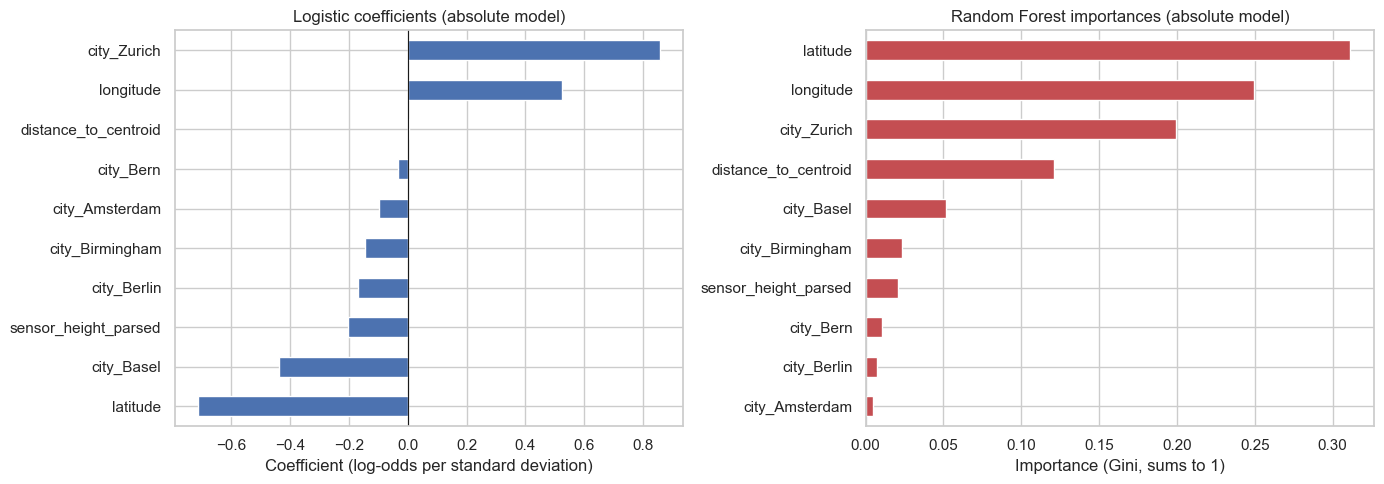

Logistic coefficients:
latitude               -0.714
city_Basel             -0.437
sensor_height_parsed   -0.204
city_Berlin            -0.170
city_Birmingham        -0.146
city_Amsterdam         -0.099
city_Bern              -0.034
distance_to_centroid    0.005
longitude               0.526
city_Zurich             0.858
dtype: float64

RF importances:
city_Amsterdam          0.005
city_Berlin             0.008
city_Bern               0.011
sensor_height_parsed    0.021
city_Birmingham         0.023
city_Basel              0.052
distance_to_centroid    0.121
city_Zurich             0.200
longitude               0.249
latitude                0.311
dtype: float64


In [12]:
# Feature names after the ColumnTransformer (numeric + one-hot city)
feat_names = logit.best_estimator_.named_steps['pre'].get_feature_names_out()
clean = [n.replace('num__', '').replace('cat__', '') for n in feat_names]

logit_clf = logit.best_estimator_.named_steps['clf']
coef = pd.Series(logit_clf.coef_[0], index=clean).sort_values()

rf_clf = rf.best_estimator_.named_steps['clf']
imp = pd.Series(rf_clf.feature_importances_, index=clean).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
coef.plot.barh(ax=axes[0], color='#4C72B0')
axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_title('Logistic coefficients (absolute model)')
axes[0].set_xlabel('Coefficient (log-odds per standard deviation)')
imp.plot.barh(ax=axes[1], color='#C44E52')
axes[1].set_title('Random Forest importances (absolute model)')
axes[1].set_xlabel('Importance (Gini, sums to 1)')
plt.tight_layout(); plt.show()

print('Logistic coefficients:'); print(coef.round(3))
print('\nRF importances:'); print(imp.round(3))

### 6.1 Reading the results

- **Climate geography dominates the absolute model.** The RandomForest leans on `latitude` (importance 0.31), `longitude` (0.25) and `city_Zurich` (0.20); the logistic coefficients agree (city_Zurich +0.86, latitude −0.71). These encode *which climate a station sits in* — the between-city signal D1 already identified.
- **The within-city signal is essentially absent.** `distance_to_centroid`, our only true within-city geographic feature, has RF importance 0.12 and a logistic coefficient of just +0.005 (indistinguishable from zero). This is precisely why Model B fails: the feature meant to capture microclimate position carries almost no information about local hotspot status. `sensor_height_parsed` is also negligible (0.02), as expected given it is nearly constant (2–4 m).

### 6.2 Screening recommendation

The absolute model, at the cost-optimal threshold of 0.44 (Section 5.3), flags stations for site investigation. It catches **77% of true absolute hotspots at 38% precision**. This makes it a usable cross-city screen, tuned to prefer false alarms over missed hotspots. But absolute risk is dominated by which city a station is in, so this screen mostly re-states the climate ranking already visible in D1. The actionable question for a city planner with a fixed local budget is different. They need to know which stations are local hotspots *within* their city. That question is **not answerable from the geography we have**, since Model B performs at chance. The honest recommendation to a planner is therefore twofold. Use the cross-city screen to prioritise *which cities* warrant attention. Do **not** rely on this model to rank stations *within* a city until microclimate data is added.

### 6.3 Limitations

- **Microclimate needs data we do not have.** The within-city model fails because the true drivers (land cover, imperviousness, building density, greenspace, proximity to water) are absent. Latitude/longitude/distance-to-centroid are too crude.
- **Absolute model is climate-dominated.** Its skill largely reflects the obvious between-city temperature differences; it is a weak "screen" in the sense of telling a single city anything new.
- **Relative label is relative.** A within-city hotspot in cool Amsterdam is not hot in absolute terms.
- **Small N** (375 stations, 6 cities); within-city quartiles for Amsterdam/Berlin rest on 10 stations each.
- **Associations, not causes.** The models show that geography and heat risk move together. They do not show that geography causes the heat. The strong city effect, for example, may stand in for unmeasured differences such as land cover or sensor placement. The model can say *where* risk is likely, but not *why*.

### 6.4 Outlook

In the next final deliverable, two analyses from this deliverable are worth deepening. Both are possible with the data we already have.

- **Uncertainty quantification.** Add bootstrap confidence intervals to the per-station risk metrics and to the model comparison. This answers whether the gap between the absolute model (ROC-AUC 0.69) and chance (0.52) holds up at N = 375, and lets us report the final conclusions as ranges rather than single numbers, so it is clear how confident we can actually be.
- **Cross-city transfer.** Train on some cities and test on a held-out city (GroupKFold). This tests whether the absolute model generalizes to a city it has never seen.

Improving the within-city model itself would require external data, such as land cover or imperviousness around each station. That lies beyond the scope of our work. We note it as the clearest path for follow-up work. The contrast in this deliverable is the evidence for why such data is the missing ingredient.